<a href="https://colab.research.google.com/github/HafizRizqi/PCVK_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

1. Buatlah fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element
Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari
openCV,

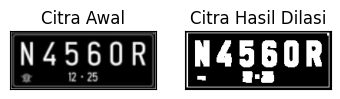

In [12]:
# Dilasi tanpa library

def dilasi_citra(F, w):

    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):

            temp = F[i-constant1:i+constant1+1,
                     j-constant1:j+constant1+1]

            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()

2. Buatlah program implementasi operasi dilasi Structuring Element Dilasi (SED)
berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV,

[[1 1 1]
 [1 1 1]
 [1 1 1]]


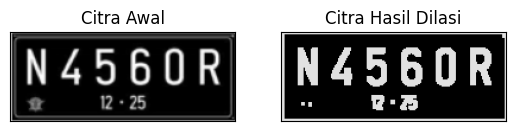

In [13]:
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png')
#img = cv2.imread(morp.jpg(),)

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint16)
dilasi = cv2.dilate(thresh, kernel, iterations=1)

print(kernel)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])

plt.show()

3. Buatlah fungsi erosi serta tampilkan hasil erosi pada citra dengan Structuring Element
Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari
openCV,

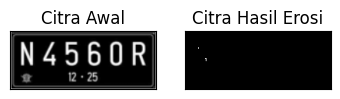

In [14]:
# Erosi Tanpa Library
def erosi_citra(F, k):
#size image
    m,n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i-constant:i+constant+1,
                     j-constant:j+constant+1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()

4. Buatlah program implementasi operasi dilasi Structuring Element Erosi (SE) berbentuk
square 5 x 5 dengan menggunakan library morphology dari openCV,

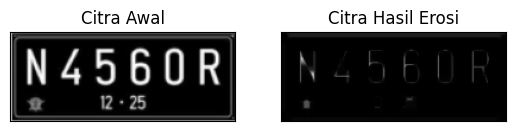

In [15]:
# EROSI LIBRARY

img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png')

kernel = np.ones((5,5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])

plt.show()

5. Buatlah program implementasi operasi opening dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV,

Operasi Opening Menggunakan tanpa Library Morphology

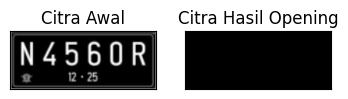

In [17]:
img_o = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret0, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)

k = 7

imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

Operasi Opening Menggunakan tanpa Library Morphology

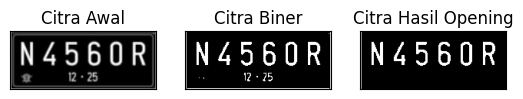

In [22]:
# Dengan Menggunakan Library

img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint8)

openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.show()

6. Buatlah program implementasi operasi closing dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV,

operasi closing tanpa library morphology

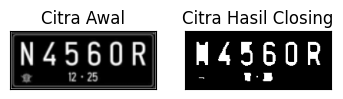

In [24]:
img_c = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)

k = 7

imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.show()

operasi closing dengan library morphology

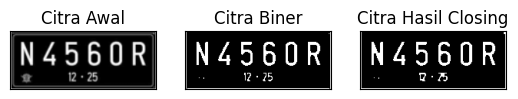

In [26]:
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)

kernel = np.ones((3,3), np.uint8)

closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])

plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.show()

7. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Cross 3 x 3 dan 5 x 5,

SED = Cross 3


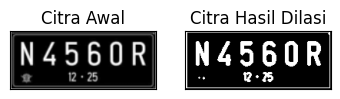

SED = Cross 5


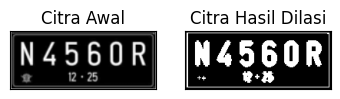

In [36]:
#Dilasi Cross SED
def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    # SED = np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)

    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1,
                     j-constant1:j+constant1+1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

print('SED = Cross 3')

img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 3

imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()

def dilasi_citra(F, w):
    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    # SED = np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)

    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1,
                     j-constant1:j+constant1+1]

            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Cross 5')

img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 5

imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()

8. Buatlah program implementasi operasi dilasi dengan Structuring Element berbentuk
Circular 3 x 3 dan 5 x 5,

SED = Circle 3


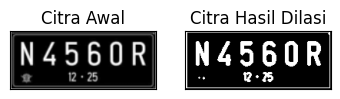

SED = Circle 5


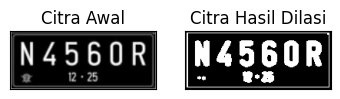

In [37]:
# Dilasi Circular SED

def dilasi_citra(F, w):

    # size image
    p, q = F.shape

    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))

    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i-constant1:i+constant1+1,
                     j-constant1:j+constant1+1]

            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Circle 3')

img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 3

imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()


print('SED = Circle 5')

img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)

w = 5

imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.show()

9. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Rectangle 3 x 5 dan 5 x 7,

SE = Rectangle 3x5


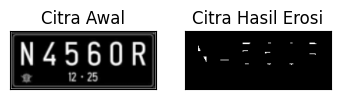

SE = Rectangle 5x7


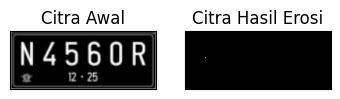

In [38]:
# Erosi Cross SE

def erosi_citra(F, p, l):

    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))  # SE persegi panjang

    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2

    # print(SE)

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i-constant1:i+constant1+1,
                     j-constant2:j+constant2+1]

            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SE = Rectangle 3x5')

img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

p = 5
l = 3

imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()


print('SE = Rectangle 5x7')

img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.png', 0)

ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

p = 7
l = 5

imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()

10. Buatlah program implementasi operasi erosi dengan Structuring Element berbentuk
Line Vertikal 3 dan 5, sehingga menghasilkan tampilan seperti di bawah ini: (Gunakan
gambar j.png)

SE = Line Vertikal 3


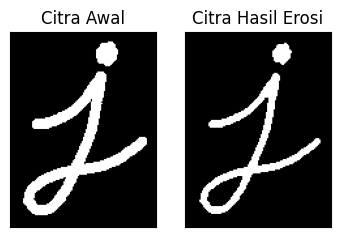

SE = Line Vertikal 5


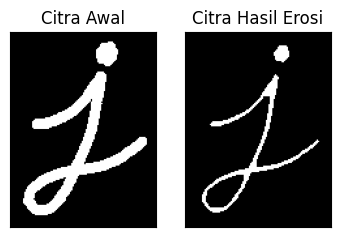

In [39]:
# Erosi Line Vertikal SE

def erosi_citra(F, k):

    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))  # SE line vertikal

    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i-constant:i+constant+1,
                     j-constant:j+constant+1]

            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SE = Line Vertikal 3')

img_e = cv2.imread('/content/drive/MyDrive/PCVK/j.png', 0)

ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

k = 3

imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()


print('SE = Line Vertikal 5')

img_e = cv2.imread('/content/drive/MyDrive/PCVK/j.png', 0)

ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)

k = 5

imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.show()

11. TopHat

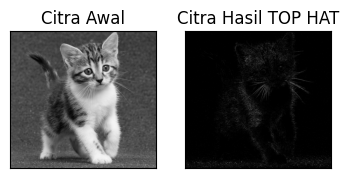

In [41]:
# Getting the kernel to be used in Top-Hat

filterSize = (3, 3)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    filterSize
)

# Reading the image named 'input.jpg'

img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')

img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation

tophat_img = cv2.morphologyEx(
    img,
    cv2.MORPH_TOPHAT,
    kernel
)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])

plt.show()

12. BLACKHAT

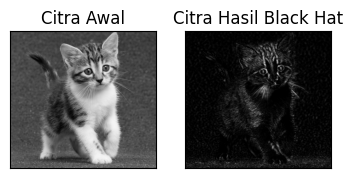

In [42]:
filterSize = (3, 3)

kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    filterSize
)

# Reading the image named 'input.jpg'

img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')

img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation

#tophat_img = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)

Kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (13, 5)
)

blackhat = cv2.morphologyEx(
    img,
    cv2.MORPH_BLACKHAT,
    Kernel
)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])

plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])

plt.show()

13. Skeleton

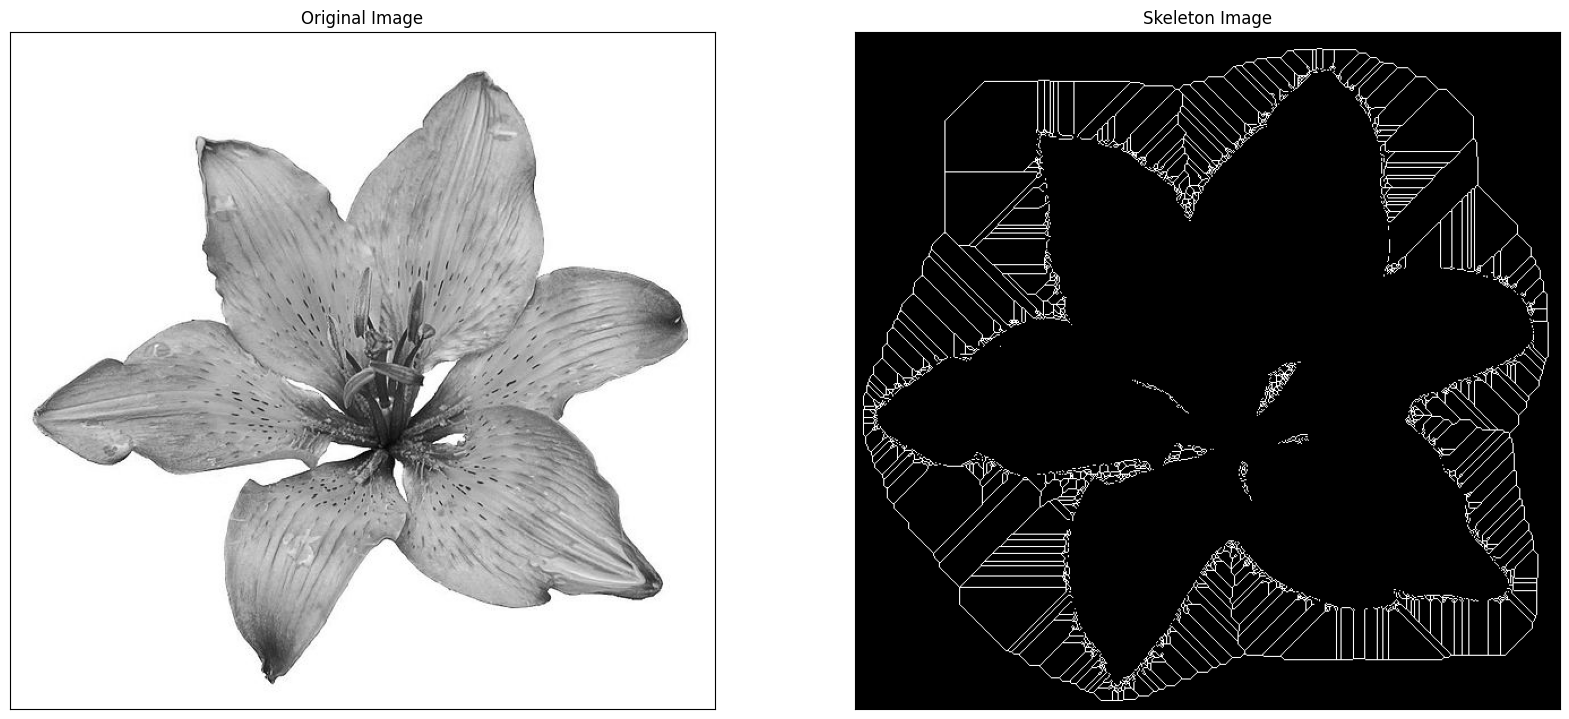

In [43]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/PCVK/lily.jpg', 0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])

plt.savefig("binary and bin_skeleton.png")
plt.show()

14. Skeleton Inverse

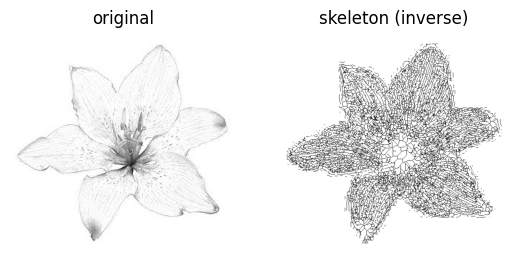

In [44]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/PCVK/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

15. Thickening

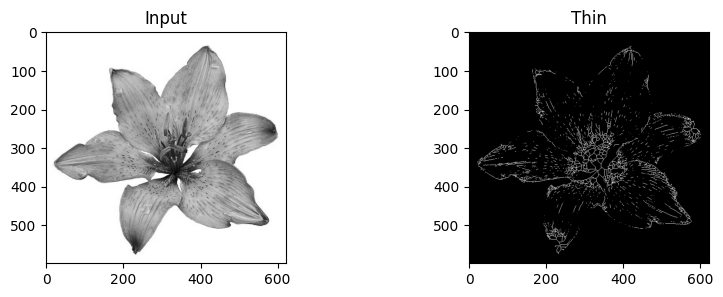

In [45]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(
    color.rgb2gray(
        io.imread('/content/drive/MyDrive/PCVK/lily.jpg')
    )
)

image_binary = image < 0.5

out = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

# Tugas Praktikum Morfologi
melibatkan implementasi dataset KTP yang terdapat dalam
Modul 7. Dalam tugas ini, kita akan menggunakan semua informasi yang disediakan dalam
modul Morfologi dan menerapkan sejumlah nilai tambahan dalam kode sumber. Tujuannya
adalah agar citra KTP dapat terbaca dengan baik ketika teknik morfologi diterapkan pada citra
tersebut.

Saving ktp_fulan.jpg to ktp_fulan.jpg
Nama file: ktp_fulan.jpg
Ukuran gambar (tinggi, lebar): (458, 694)


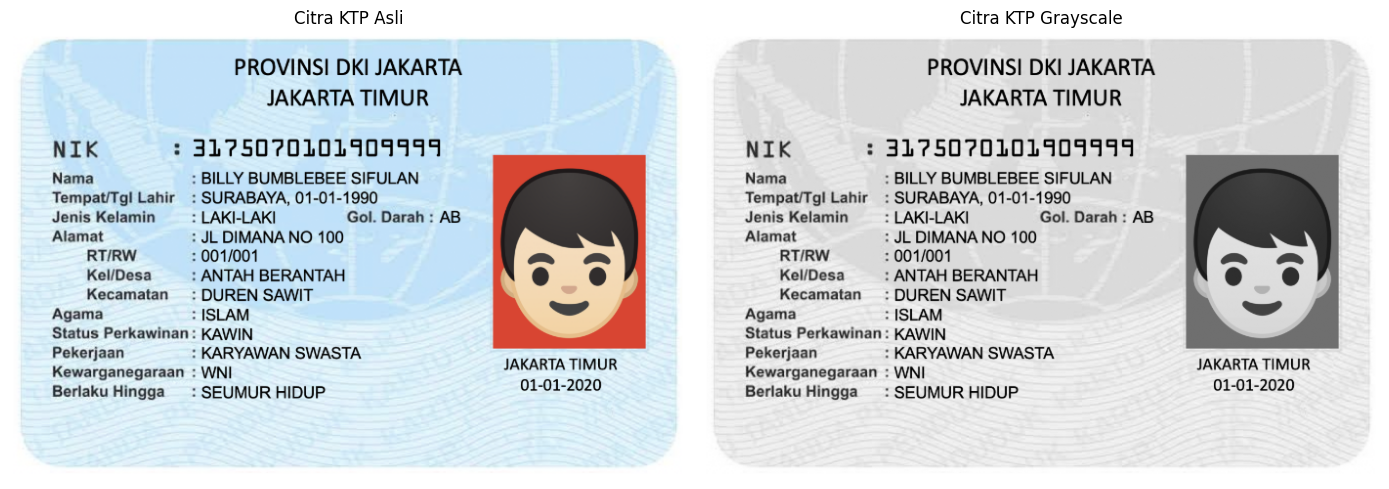

In [46]:
# 1. Memuat gambar KTP
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded_ktp = files.upload()
ktp_filename = next(
    (name for name in uploaded_ktp.keys()
     if name.lower().endswith((".jpg", ".jpeg", ".png"))),
    None
)

if ktp_filename is None:
    raise ValueError("Unggah gambar KTP dengan format JPG, JPEG, atau PNG.")

ktp_bgr = cv2.imread(ktp_filename)
if ktp_bgr is None:
    raise FileNotFoundError(f"Gambar tidak dapat dibaca: {ktp_filename}")

ktp_rgb = cv2.cvtColor(ktp_bgr, cv2.COLOR_BGR2RGB)
ktp_gray = cv2.cvtColor(ktp_bgr, cv2.COLOR_BGR2GRAY)

print("Nama file:", ktp_filename)
print("Ukuran gambar (tinggi, lebar):", ktp_gray.shape)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(ktp_rgb)
plt.title("Citra KTP Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ktp_gray, cmap="gray")
plt.title("Citra KTP Grayscale")
plt.axis("off")
plt.tight_layout()
plt.show()

**Analisa hasil**
Pada citra grayscale, tulisan tetap terlihat, tetapi warna latar dan pola keamanan KTP masih menimbulkan variasi intensitas. Oleh karena itu, kontras tulisan diperbaiki sebelum proses morfologi.

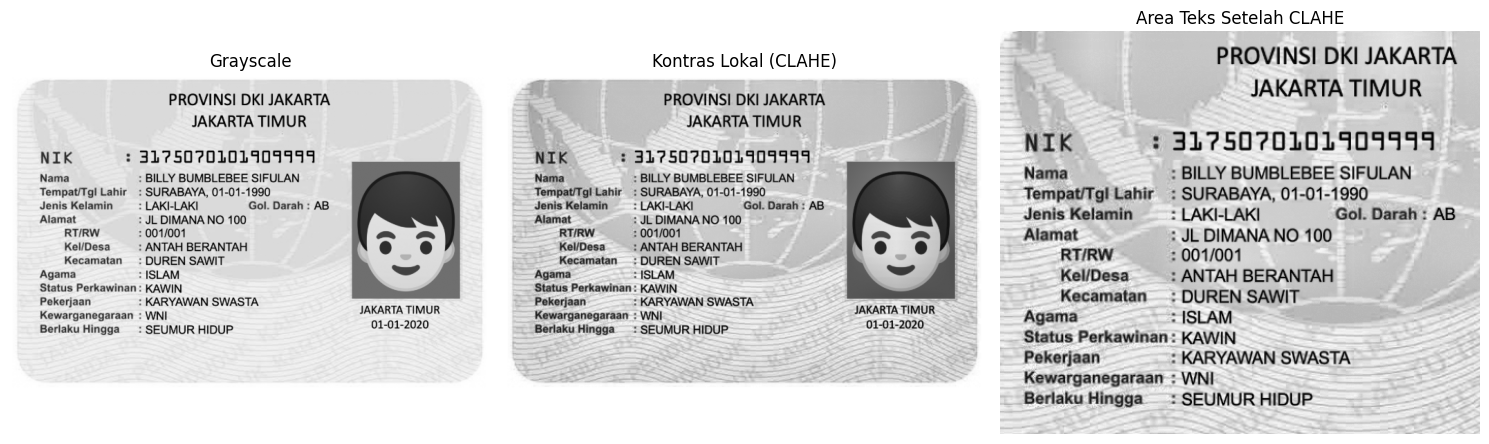

In [47]:
# 2. Meningkatkan kontras dan memilih area teks utama
# CLAHE memperjelas kontras secara lokal tanpa mengubah ukuran citra.
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
ktp_clahe = clahe.apply(ktp_gray)

h, w = ktp_gray.shape
# Crop area judul dan informasi utama di sisi kiri KTP.
# Crop ini menghindari area foto agar proses pembacaan tulisan lebih fokus.
y1, y2 = int(0.03 * h), int(0.88 * h)
x1, x2 = int(0.03 * w), int(0.70 * w)
ktp_roi_gray = ktp_gray[y1:y2, x1:x2]
ktp_roi_clahe = clahe.apply(ktp_roi_gray)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(ktp_gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ktp_clahe, cmap="gray")
plt.title("Kontras Lokal (CLAHE)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ktp_roi_clahe, cmap="gray")
plt.title("Area Teks Setelah CLAHE")
plt.axis("off")
plt.tight_layout()
plt.show()

**Penjelasan langkah 2**. CLAHE (clipLimit=2.0, tileGridSize=(8,8)) digunakan untuk meningkatkan kontras lokal. Area teks utama dipotong agar tulisan tidak terganggu oleh warna dan detail foto di sisi kanan KTP.

**Analisa hasil**. Kontras huruf terhadap latar menjadi lebih mudah diamati. Pemotongan hanya dilakukan untuk analisis tulisan; variabel citra KTP asli tetap utuh.

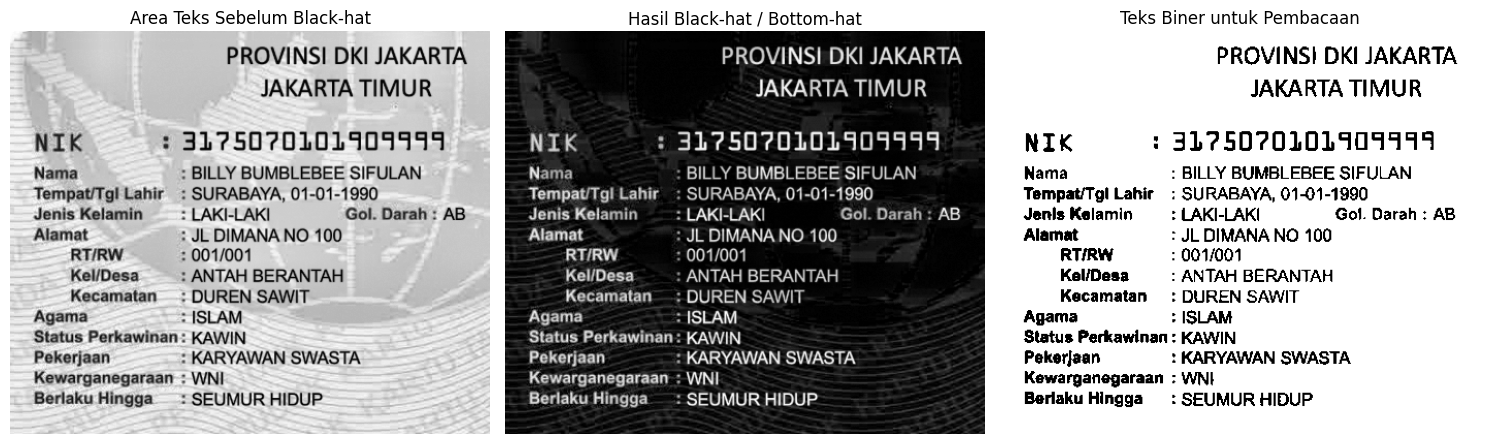

In [48]:
# 3. Black-hat / Bottom-hat untuk menonjolkan tulisan gelap
# Kernel persegi panjang 31 x 9 dipilih berdasarkan ukuran huruf pada citra ini.
se_bh = cv2.getStructuringElement(cv2.MORPH_RECT, (31, 9))
ktp_bottomhat = cv2.morphologyEx(
    ktp_roi_clahe, cv2.MORPH_BLACKHAT, se_bh
)

# Otsu mengubah hasil black-hat menjadi mask biner.
_, ktp_text_mask = cv2.threshold(
    ktp_bottomhat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Balik warna agar hasil tampil dengan latar putih dan tulisan hitam.
ktp_readable = cv2.bitwise_not(ktp_text_mask)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(ktp_roi_clahe, cmap="gray")
plt.title("Area Teks Sebelum Black-hat")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ktp_bottomhat, cmap="gray")
plt.title("Hasil Black-hat / Bottom-hat")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ktp_readable, cmap="gray")
plt.title("Teks Biner untuk Pembacaan")
plt.axis("off")
plt.tight_layout()
plt.show()

**Penjelasan langkah 3.** Black-hat (bottom-hat) menghitung perbedaan antara hasil closing dan citra asal sehingga detail gelap yang lebih kecil daripada structuring element dapat ditonjolkan. Kernel persegi panjang 31 × 9 dipilih untuk skala tulisan pada gambar ini. Threshold Otsu memisahkan hasil menjadi piksel tulisan (putih) dan latar (hitam), lalu warnanya dibalik untuk tampilan akhir yang lebih familiar.

**Analisa hasil**. Dibandingkan grayscale, tulisan utama lebih terpisah dari pola latar KTP. Ukuran kernel perlu disesuaikan jika gambar yang digunakan memiliki resolusi atau skala tulisan berbeda.

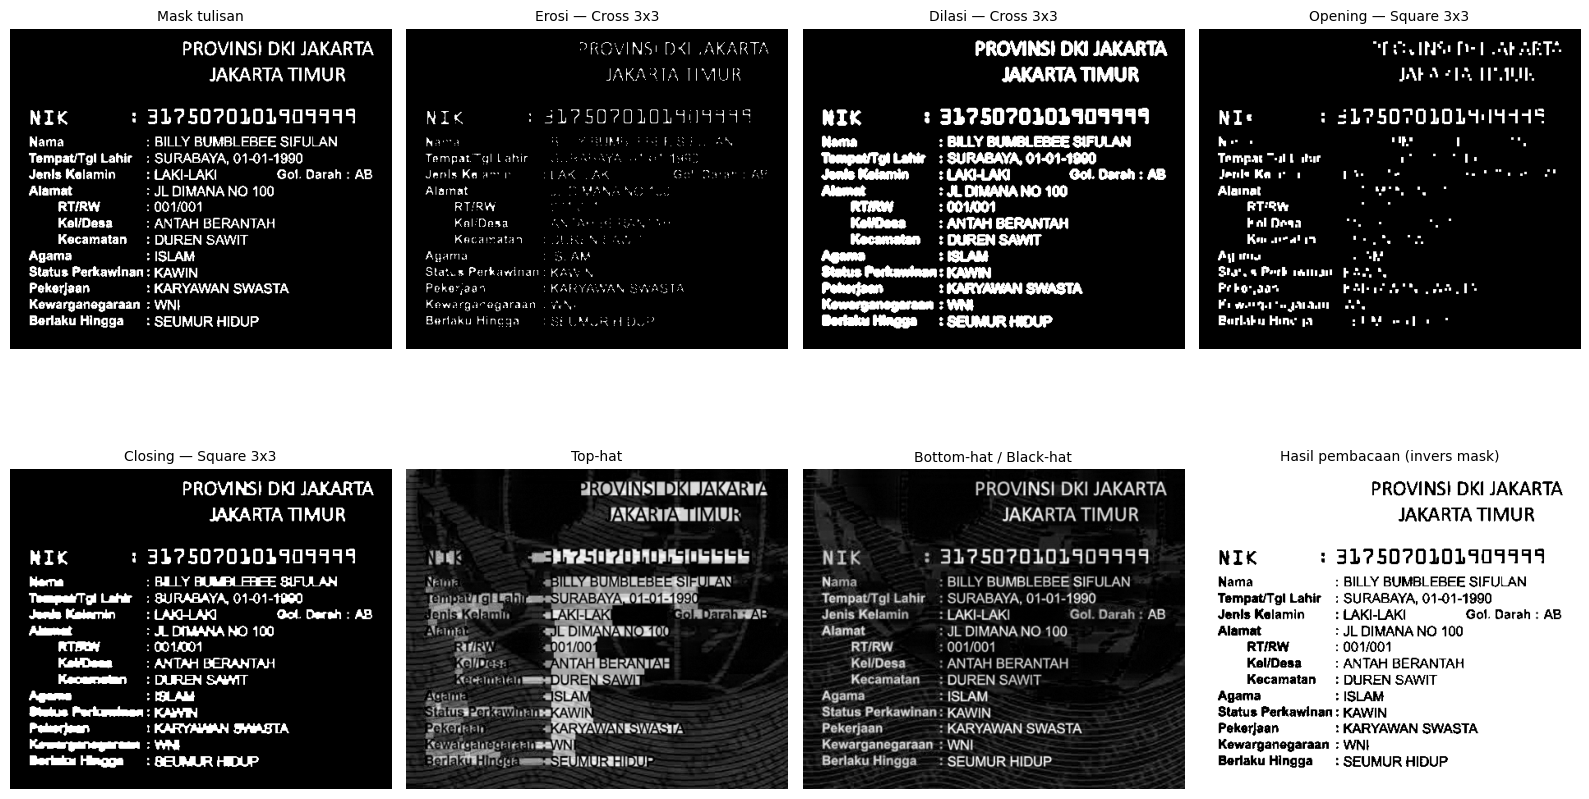

In [49]:
# 4. Membandingkan operasi morfologi pada mask tulisan
# Mask menggunakan tulisan putih sebagai objek dan latar hitam.
se_cross3 = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
se_square3 = np.ones((3, 3), dtype=np.uint8)

ktp_erosi = cv2.erode(ktp_text_mask, se_cross3, iterations=1)
ktp_dilasi = cv2.dilate(ktp_text_mask, se_cross3, iterations=1)
ktp_opening = cv2.morphologyEx(ktp_text_mask, cv2.MORPH_OPEN, se_square3)
ktp_closing = cv2.morphologyEx(ktp_text_mask, cv2.MORPH_CLOSE, se_square3)

# Top-hat dan bottom-hat diterapkan pada citra grayscale, bukan mask biner.
ktp_tophat = cv2.morphologyEx(
    ktp_roi_clahe, cv2.MORPH_TOPHAT, se_bh
)

hasil_morfologi = [
    ("Mask tulisan", ktp_text_mask),
    ("Erosi — Cross 3x3", ktp_erosi),
    ("Dilasi — Cross 3x3", ktp_dilasi),
    ("Opening — Square 3x3", ktp_opening),
    ("Closing — Square 3x3", ktp_closing),
    ("Top-hat", ktp_tophat),
    ("Bottom-hat / Black-hat", ktp_bottomhat),
    ("Hasil pembacaan (invers mask)", ktp_readable),
]

plt.figure(figsize=(16, 10))
for i, (judul, hasil) in enumerate(hasil_morfologi, 1):
    plt.subplot(2, 4, i)
    plt.imshow(hasil, cmap="gray")
    plt.title(judul, fontsize=10)
    plt.axis("off")
plt.tight_layout()
plt.show()

**Penjelasan langkah 4**. Erosi mengurangi ketebalan objek putih, sedangkan dilasi mempertebalnya. Opening adalah erosi yang diikuti dilasi dan dapat menghilangkan noise kecil; closing adalah dilasi yang diikuti erosi dan dapat menutup celah kecil. Top-hat menonjolkan detail terang, sedangkan bottom-hat/black-hat menonjolkan detail gelap.

**Analisa hasil**. Operasi tidak selalu memperbaiki tulisan secara bersamaan. Erosi yang terlalu kuat dapat menghilangkan bagian huruf; dilasi yang terlalu kuat dapat menyatukan huruf berdekatan. Opening dan closing dengan kernel 3 × 3 dipakai sebagai perbandingan ringan. Pada gambar ini, hasil black-hat yang di-threshold menjadi tampilan fokus untuk memeriksa tulisan

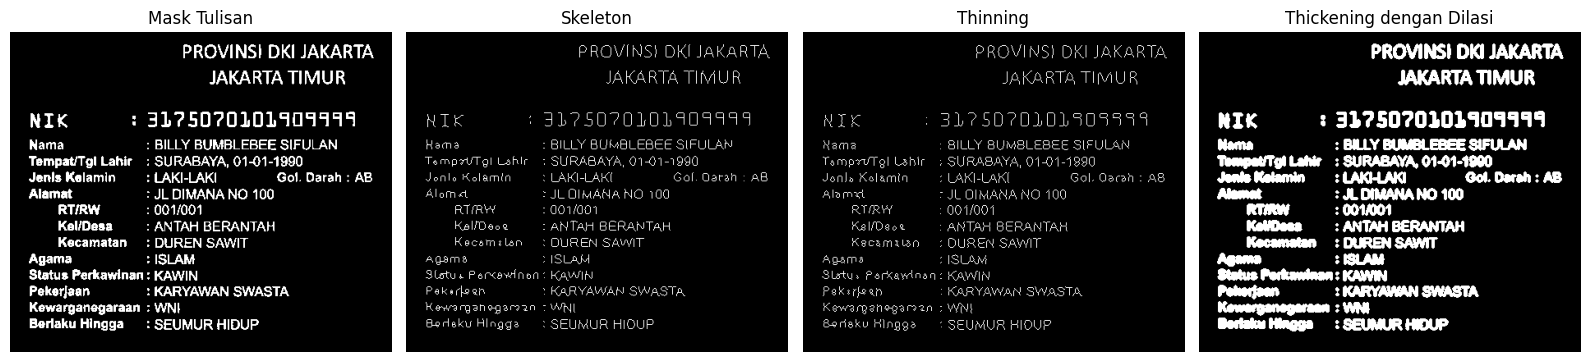

In [50]:
# 5. Skeleton, thinning, dan penebalan tulisan
from skimage.morphology import skeletonize, thin

# skeletonize/thin menerima mask boolean; True berarti bagian objek.
ktp_skeleton = skeletonize(ktp_text_mask > 0)
ktp_thinning = thin(ktp_text_mask > 0)

# Penebalan sesungguhnya dicontohkan dengan dilasi satu kali.
ktp_thickening = cv2.dilate(
    ktp_text_mask, se_cross3, iterations=1
)

fig, ax = plt.subplots(1, 4, figsize=(16, 5))
ax[0].imshow(ktp_text_mask, cmap="gray")
ax[0].set_title("Mask Tulisan")
ax[1].imshow(ktp_skeleton, cmap="gray")
ax[1].set_title("Skeleton")
ax[2].imshow(ktp_thinning, cmap="gray")
ax[2].set_title("Thinning")
ax[3].imshow(ktp_thickening, cmap="gray")
ax[3].set_title("Thickening dengan Dilasi")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

Penjelasan langkah 5. Skeleton mereduksi objek menjadi rangka tipis, sedangkan thinning menipiskan piksel objek secara bertahap. Untuk contoh penebalan, dilasi digunakan untuk menambah ketebalan goresan tulisan.

Analisa hasil. Skeleton dan thinning berguna untuk melihat struktur rangka huruf, bukan sebagai hasil akhir paling mudah dibaca. Penebalan dapat membantu goresan huruf yang tipis, tetapi jika diulang terlalu banyak dapat membuat huruf saling menyatu.

In [51]:
# 6. Menyimpan hasil akhir pemrosesan area teks
output_path = "/content/ktp_hasil_morfologi.png"
berhasil_simpan = cv2.imwrite(output_path, ktp_readable)

if berhasil_simpan:
    print("Hasil tersimpan di:", output_path)
else:
    raise IOError("Gagal menyimpan hasil morfologi.")

# Untuk mengunduh hasil ke komputer, jalankan dua baris berikut bila diperlukan:
# from google.colab import files
# files.download(output_path)

Hasil tersimpan di: /content/ktp_hasil_morfologi.png


#Analisa akhir dan kesimpulan
Berdasarkan percobaan, citra KTP diubah menjadi grayscale dan ditingkatkan kontras lokalnya agar perbedaan intensitas tulisan dan latar lebih jelas. Operasi black-hat/bottom-hat dengan structuring element persegi panjang 31 × 9, disertai threshold Otsu, menghasilkan mask yang menonjolkan tulisan gelap pada area informasi. Hasil invers mask disimpan sebagai ktp_hasil_morfologi.png untuk membantu memeriksa teks utama.

Erosi, dilasi, opening, dan closing memberikan perubahan bentuk yang berbeda sesuai ukuran serta bentuk structuring element. Skeleton dan thinning memperlihatkan rangka tulisan, sementara penebalan melalui dilasi membuat goresan menjadi lebih tebal. Parameter terbaik dapat berbeda jika resolusi atau pencahayaan gambar berubah; karena itu hasil visual perlu diperiksa dan kernel dapat disesuaikan. Pemrosesan ini membantu meningkatkan keterbacaan visual, tetapi tidak menjamin semua karakter terbaca benar secara otomatis.